# Thermal Concentric-C Acuity
## A Physics-Based Simulation and Classical Computer Vision Study

**Project:** `thermal-c-acuity`  
**Application:** RoboCup Rescue — thermal detection of a two-level concentric-C target

---

## 1. What is this project about?

This project studies one question:

> **How well can a thermal imaging system recognize a two-level concentric-C target when imaging conditions become difficult?**

The target contains two C-shaped rings:

- an outer C
- an inner C
- the same center
- the same opening direction

A complete circle is easy to recognize. A C is harder because the imaging system must preserve the opening.

This notebook uses a **physics-based synthetic thermal image** and **classical computer vision**. It does not train a machine-learning model.

The study examines:

1. Distance
2. Blur
3. Thermal noise
4. Thermal contrast
5. Camera resolution

---

# 2. Complete pipeline

```text
Concentric-C geometry
        ↓
Temperature map
        ↓
Distance / camera simulation
        ↓
Blur
        ↓
Thermal noise
        ↓
Preprocessing
        ↓
Contour extraction
        ↓
Two-level C detector
        ↓
Repeated trials
        ↓
Detection reliability
```

A positive result means the algorithm recovered the two-level C structure.

A negative result means the structure was not reliably recoverable under the tested condition.

---

# 3. What is a two-level concentric C?

The target is made from two circular rings with an opening.

| Property | Outer C | Inner C |
|---|---:|---:|
| Radius | 30 px | 15 px |
| Ring width | 6 px | 4 px |
| Opening | 45° | 45° |
| Center | Same | Same |
| Opening direction | Same | Same |

The radius ratio is:

\[
30/15 = 2.0
\]

The detector requires a minimum radius ratio of 1.3.

The important feature is not only that there are two rings. They must be **two C-shaped rings with the same center and compatible opening direction**.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

RNG_SEED = 42
rng = np.random.default_rng(RNG_SEED)

print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

NumPy: 2.1.3
OpenCV: 5.0.0
Matplotlib: 3.10.0


---

# 4. Reference thermal scene

The main synthetic sensor is **320 × 256 pixels**.

The background is **25 °C** and the target is **40 °C**.

Therefore:

\[
\Delta T = 40 - 25 = 15\, ^\circ C
\]

These are simulation parameters, not measurements of a particular real thermal camera.

In [2]:
WIDTH, HEIGHT = 320, 256

BACKGROUND_TEMP = 25.0
TARGET_TEMP = 40.0
CONTRAST = TARGET_TEMP - BACKGROUND_TEMP

CX, CY = WIDTH // 2, HEIGHT // 2

OUTER_RADIUS, OUTER_WIDTH = 30.0, 6.0
INNER_RADIUS, INNER_WIDTH = 15.0, 4.0
GAP_ANGLE = 45.0

THRESHOLD = 80
KERNEL_SIZE = 3

print(f"Scene: {WIDTH} × {HEIGHT} pixels")
print(f"Background: {BACKGROUND_TEMP:.1f} °C")
print(f"Target: {TARGET_TEMP:.1f} °C")
print(f"Contrast: {CONTRAST:.1f} °C")

Scene: 320 × 256 pixels
Background: 25.0 °C
Target: 40.0 °C
Contrast: 15.0 °C


---

# 5. Generate the C pattern

A C is created with two simple rules.

**Ring rule:** keep pixels inside a circular annulus.

**Gap rule:** remove a 45° angular sector.

So:

```text
C = ring AND NOT gap
```

This gives us an exact mathematical ground truth.

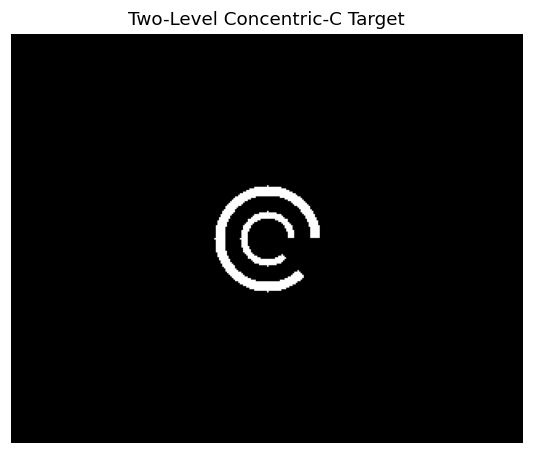

In [3]:
def draw_c_mask(cx, cy, radius, width, gap_angle=45.0,
                height=HEIGHT, width_img=WIDTH):
    y, x = np.ogrid[:height, :width_img]

    distance = np.sqrt((x - cx) ** 2 + (y - cy) ** 2)

    ring = (
        (distance >= radius - width / 2) &
        (distance <= radius + width / 2)
    )

    angle = np.degrees(np.arctan2(y - cy, x - cx))
    angle = (angle + 360.0) % 360.0

    gap = (angle >= 0.0) & (angle <= gap_angle)

    return ring & ~gap


def make_two_level_c_mask():
    outer = draw_c_mask(CX, CY, OUTER_RADIUS, OUTER_WIDTH)
    inner = draw_c_mask(CX, CY, INNER_RADIUS, INNER_WIDTH)
    return outer | inner


target_mask = make_two_level_c_mask()
target_bitmap = (target_mask * 255).astype(np.uint8)

plt.figure(figsize=(6, 5))
plt.imshow(target_bitmap, cmap="gray", vmin=0, vmax=255)
plt.title("Two-Level Concentric-C Target")
plt.axis("off")
plt.show()

---

# 6. Convert geometry into temperature

The binary target is converted into a thermal scene:

```text
background → 25 °C
C target   → 40 °C
```

The model is intentionally simple so that individual imaging effects can be studied separately.

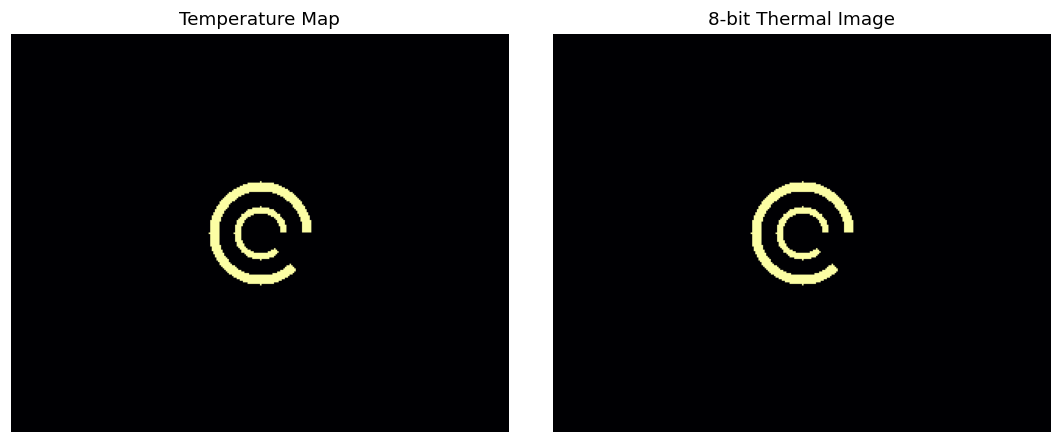

In [4]:
def create_temperature_map(
    width=WIDTH,
    height=HEIGHT,
    outer_radius=OUTER_RADIUS,
    inner_radius=INNER_RADIUS,
    outer_width=OUTER_WIDTH,
    inner_width=INNER_WIDTH,
    background_temp=BACKGROUND_TEMP,
    target_temp=TARGET_TEMP
):
    temperature = np.full(
        (height, width),
        background_temp,
        dtype=np.float32
    )

    cx = width // 2
    cy = height // 2

    outer = draw_c_mask(
        cx, cy, outer_radius, outer_width,
        height=height, width_img=width
    )

    inner = draw_c_mask(
        cx, cy, inner_radius, inner_width,
        height=height, width_img=width
    )

    temperature[outer | inner] = target_temp
    return temperature


def temperature_to_uint8(
    temperature,
    min_temp=BACKGROUND_TEMP,
    max_temp=TARGET_TEMP
):
    normalized = (temperature - min_temp) / (max_temp - min_temp)
    normalized = np.clip(normalized, 0, 1)
    return (normalized * 255).astype(np.uint8)


temperature = create_temperature_map()
thermal_image = temperature_to_uint8(temperature)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(
    temperature, cmap="inferno",
    vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP
)
axes[0].set_title("Temperature Map")
axes[0].axis("off")

axes[1].imshow(thermal_image, cmap="inferno")
axes[1].set_title("8-bit Thermal Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

---

# 7. Simulate distance and blur

Distance makes the target occupy fewer pixels.

For a reference distance of 0.5 m:

\[
scale = 0.5/d
\]

This is a simplified geometric model.

Blur is also simulated with a Gaussian kernel. The model is useful for controlled experiments, but it is not a complete optical model of a real thermal camera.

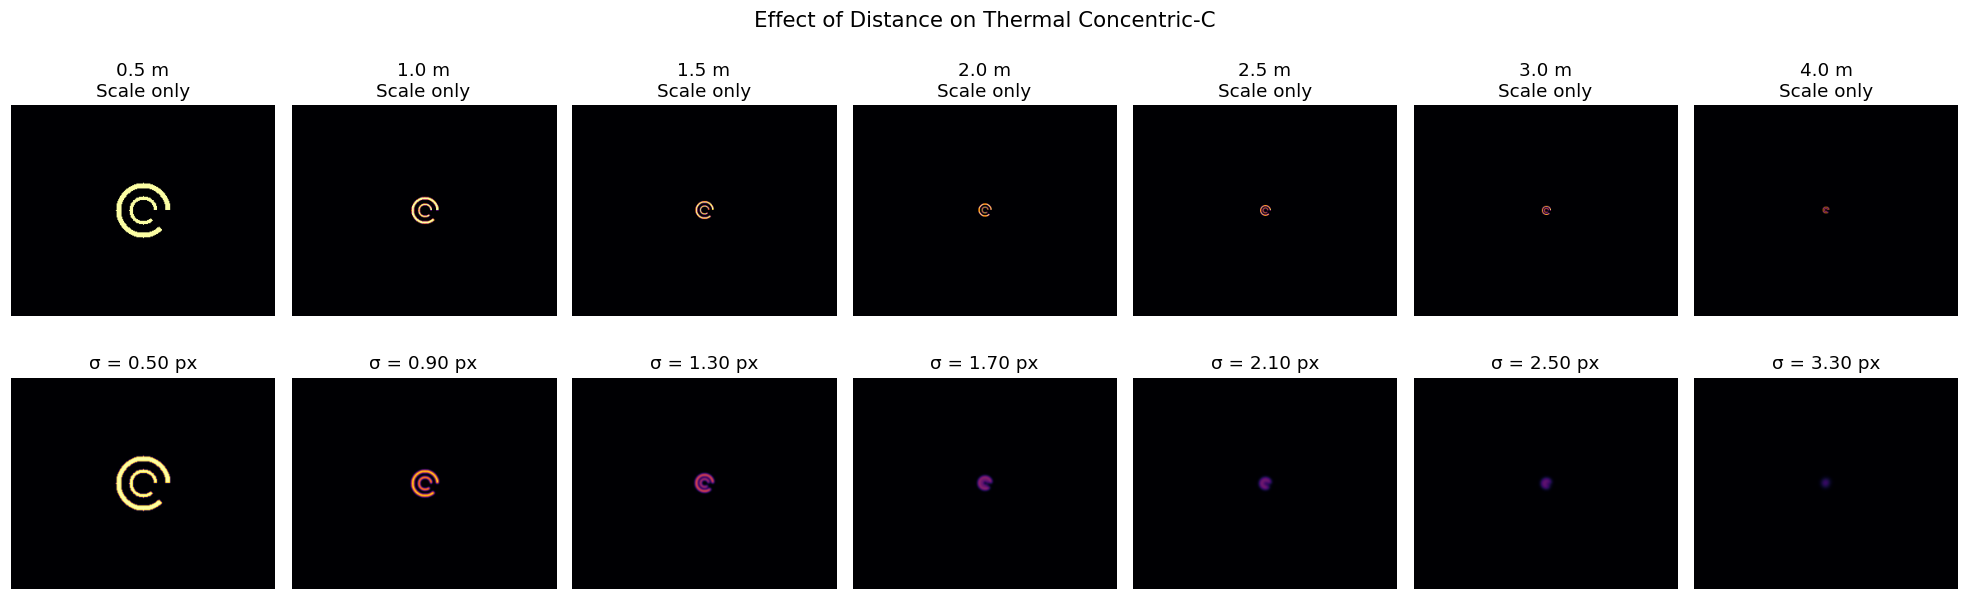

In [6]:
REFERENCE_DISTANCE = 0.5
BASE_BLUR_SIGMA = 0.5
BLUR_PER_METER = 0.8


def simulate_distance(temperature, distance):
    height, width = temperature.shape
    scale = REFERENCE_DISTANCE / distance

    target_mask = temperature > BACKGROUND_TEMP
    ys, xs = np.where(target_mask)

    if len(xs) == 0:
        return temperature.copy()

    target = temperature[
        ys.min():ys.max() + 1,
        xs.min():xs.max() + 1
    ]

    new_w = max(2, int(target.shape[1] * scale))
    new_h = max(2, int(target.shape[0] * scale))

    resized = cv2.resize(
        target,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    result = np.full(
        (height, width),
        BACKGROUND_TEMP,
        dtype=np.float32
    )

    start_x = width // 2 - new_w // 2
    start_y = height // 2 - new_h // 2

    end_x = start_x + new_w
    end_y = start_y + new_h

    sx1, sy1, sx2, sy2 = 0, 0, new_w, new_h
    dx1, dy1, dx2, dy2 = start_x, start_y, end_x, end_y

    if dx1 < 0:
        sx1, dx1 = -dx1, 0
    if dy1 < 0:
        sy1, dy1 = -dy1, 0
    if dx2 > width:
        sx2 -= dx2 - width
        dx2 = width
    if dy2 > height:
        sy2 -= dy2 - height
        dy2 = height

    result[dy1:dy2, dx1:dx2] = resized[sy1:sy2, sx1:sx2]
    return result


def simulate_blur(temperature, distance):
    sigma = (
        BASE_BLUR_SIGMA +
        BLUR_PER_METER * (distance - REFERENCE_DISTANCE)
    )
    sigma = max(0.1, sigma)

    return cv2.GaussianBlur(
        temperature,
        (0, 0),
        sigmaX=sigma,
        sigmaY=sigma
    )


distances = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0]

fig, axes = plt.subplots(
    2,
    len(distances),
    figsize=(18, 6)
)

for i, d in enumerate(distances):

    # -----------------------------
    # Row 1: Distance scaling only
    # -----------------------------
    scaled = simulate_distance(temperature, d)

    axes[0, i].imshow(
        scaled,
        cmap="inferno",
        vmin=BACKGROUND_TEMP,
        vmax=TARGET_TEMP
    )

    axes[0, i].set_title(
        f"{d:.1f} m\nScale only"
    )

    axes[0, i].axis("off")


    # -----------------------------
    # Row 2: Scaling + blur
    # -----------------------------
    blurred = simulate_blur(
        scaled,
        d
    )

    sigma = max(
        0.1,
        BASE_BLUR_SIGMA +
        BLUR_PER_METER *
        (d - REFERENCE_DISTANCE)
    )

    axes[1, i].imshow(
        blurred,
        cmap="inferno",
        vmin=BACKGROUND_TEMP,
        vmax=TARGET_TEMP
    )

    axes[1, i].set_title(
        f"σ = {sigma:.2f} px"
    )

    axes[1, i].axis("off")


# Row labels
axes[0, 0].set_ylabel(
    "Scaled",
    fontsize=11
)

axes[1, 0].set_ylabel(
    "Scaled + Blur",
    fontsize=11
)

fig.suptitle(
    "Effect of Distance on Thermal Concentric-C",
    fontsize=14
)

plt.tight_layout()
plt.show()

---

# 8. Thermal noise

Thermal noise is modelled as zero-mean Gaussian temperature noise:

\[
T_{noisy}=T+N(0,\sigma^2)
\]

The noise level is expressed in °C.

This is a simplified **NETD-style model**. It is not a laboratory measurement of a real camera's NETD.

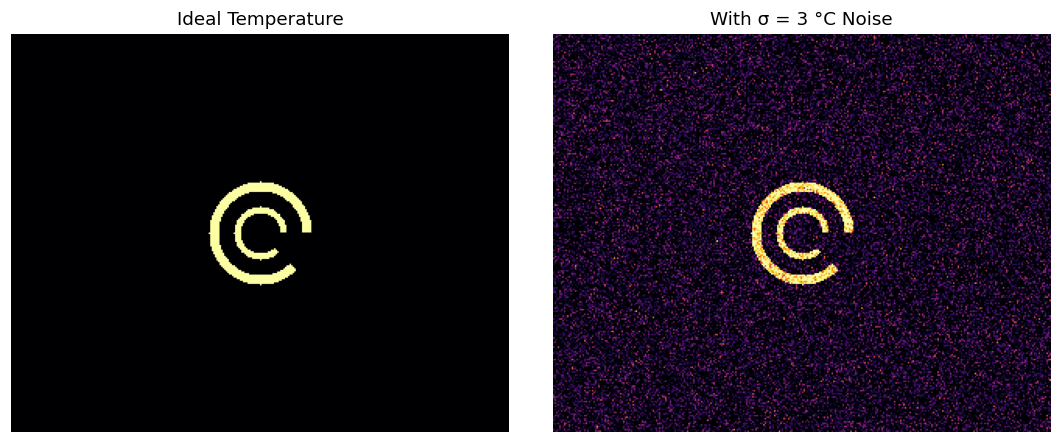

In [7]:
def add_thermal_noise(temperature, noise_sigma, generator=None):
    if generator is None:
        generator = np.random.default_rng()

    noise = generator.normal(
        0,
        noise_sigma,
        temperature.shape
    )

    return (temperature + noise).astype(np.float32)


noisy_temperature = add_thermal_noise(
    temperature,
    3.0,
    np.random.default_rng(42)
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(
    temperature, cmap="inferno",
    vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP
)
axes[0].set_title("Ideal Temperature")
axes[0].axis("off")

axes[1].imshow(
    noisy_temperature, cmap="inferno",
    vmin=BACKGROUND_TEMP, vmax=TARGET_TEMP
)
axes[1].set_title("With σ = 3 °C Noise")
axes[1].axis("off")

plt.tight_layout()
plt.show()

---

# 9. Preprocessing

The detector uses:

```text
Temperature
    ↓
8-bit conversion
    ↓
Threshold
    ↓
Morphological opening
    ↓
Clean binary image
```

The threshold is 80/255. With the 25–40 °C range, this is about **29.7 °C**.

Morphological opening removes small isolated components.

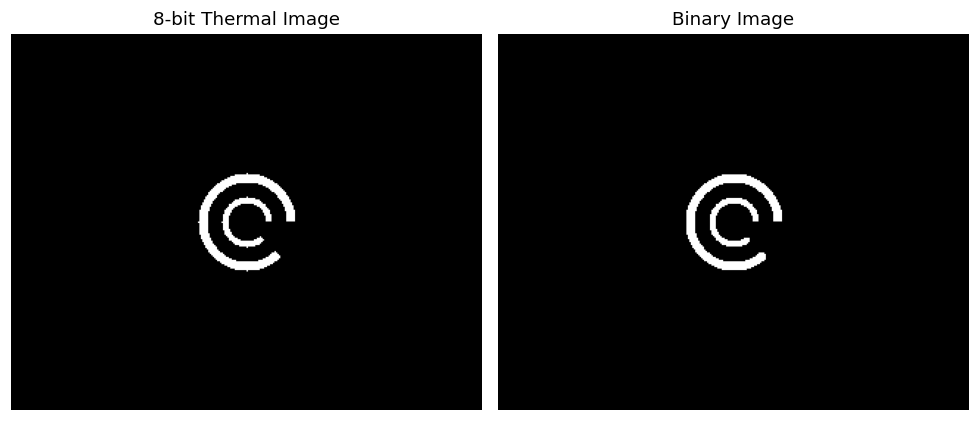

In [8]:
def preprocess(
    temperature,
    min_temp=BACKGROUND_TEMP,
    max_temp=TARGET_TEMP,
    threshold=THRESHOLD,
    kernel_size=KERNEL_SIZE
):
    image = temperature_to_uint8(
        temperature,
        min_temp,
        max_temp
    )

    _, binary = cv2.threshold(
        image,
        threshold,
        255,
        cv2.THRESH_BINARY
    )

    kernel = np.ones(
        (kernel_size, kernel_size),
        np.uint8
    )

    return cv2.morphologyEx(
        binary,
        cv2.MORPH_OPEN,
        kernel
    )


cleaned = preprocess(temperature)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(thermal_image, cmap="gray")
axes[0].set_title("8-bit Thermal Image")
axes[0].axis("off")

axes[1].imshow(cleaned, cmap="gray")
axes[1].set_title("Binary Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

---

# 10. Classical computer vision detector

No neural network is used.

The detector checks four main ideas:

1. **C shape** — the ring must contain a real opening.
2. **Same center** — the two levels must be concentric.
3. **Different radius** — the two levels must be separate.
4. **Same opening direction** — the two C openings should agree.

The final decision is therefore geometric:

```text
Outer C
   +
Inner C
   +
Same center
   +
Different radius
   +
Compatible opening direction
   ↓
Two-level concentric C
```

In [9]:
CENTER_TOLERANCE = 5.0
RADIUS_RATIO_MIN = 1.30
MIN_GAP_ANGLE = 20.0
GAP_DIRECTION_TOLERANCE = 30.0


def find_contour_candidates(binary_image):
    contours, _ = cv2.findContours(
        binary_image,
        cv2.RETR_TREE,
        cv2.CHAIN_APPROX_SIMPLE
    )

    candidates = []

    for contour in contours:
        area = cv2.contourArea(contour)

        if area <= 2:
            continue

        M = cv2.moments(contour)

        if M["m00"] == 0:
            continue

        center = np.array([
            M["m10"] / M["m00"],
            M["m01"] / M["m00"]
        ])

        (_, _), radius = cv2.minEnclosingCircle(contour)

        candidates.append({
            "contour": contour,
            "area": area,
            "center": center,
            "radius": radius
        })

    return candidates


def find_image_angular_gap(binary_image, center, radius, num_angles=360):
    height, width = binary_image.shape
    angles = np.linspace(0, 360, num_angles, endpoint=False)
    occupied = np.zeros(num_angles, dtype=bool)

    for i, angle in enumerate(angles):
        theta = np.radians(angle)
        found = False

        for r in np.linspace(
            max(1, radius - 2),
            radius + 2,
            7
        ):
            x = int(round(center[0] + r * np.cos(theta)))
            y = int(round(center[1] + r * np.sin(theta)))

            if 0 <= x < width and 0 <= y < height:
                if binary_image[y, x] > 0:
                    found = True
                    break

        occupied[i] = found

    circular = np.concatenate([occupied, occupied])

    longest_empty = 0
    current_empty = 0
    longest_end = 0

    for i, value in enumerate(circular):
        if not value:
            current_empty += 1
            if current_empty > longest_empty:
                longest_empty = current_empty
                longest_end = i
        else:
            current_empty = 0

    longest_empty = min(longest_empty, num_angles)

    gap_angle = longest_empty * 360.0 / num_angles

    gap_center_index = (
        longest_end - longest_empty / 2
    ) % num_angles

    gap_center_angle = (
        gap_center_index * 360.0 / num_angles
    )

    return gap_angle, gap_center_angle


def detect_concentric_pair(binary_image):
    candidates = find_contour_candidates(binary_image)

    if len(candidates) < 2:
        return None

    for i in range(len(candidates)):
        for j in range(i + 1, len(candidates)):

            c1 = candidates[i]
            c2 = candidates[j]

            center_distance = np.linalg.norm(
                c1["center"] - c2["center"]
            )

            larger = max(c1["radius"], c2["radius"])
            smaller = min(c1["radius"], c2["radius"])

            if smaller <= 0:
                continue

            radius_ratio = larger / smaller

            if center_distance > CENTER_TOLERANCE:
                continue

            if radius_ratio < RADIUS_RATIO_MIN:
                continue

            outer = c1 if c1["radius"] >= c2["radius"] else c2
            inner = c2 if outer is c1 else c1

            outer_gap, outer_direction = find_image_angular_gap(
                binary_image, outer["center"], outer["radius"]
            )

            inner_gap, inner_direction = find_image_angular_gap(
                binary_image, inner["center"], inner["radius"]
            )

            if (
                outer_gap < MIN_GAP_ANGLE or
                inner_gap < MIN_GAP_ANGLE
            ):
                continue

            direction_difference = abs(
                outer_direction - inner_direction
            )
            direction_difference = min(
                direction_difference,
                360 - direction_difference
            )

            if direction_difference <= GAP_DIRECTION_TOLERANCE:
                return {
                    "outer": outer,
                    "inner": inner,
                    "center_distance": center_distance,
                    "radius_ratio": radius_ratio,
                    "outer_gap_angle": outer_gap,
                    "inner_gap_angle": inner_gap,
                    "outer_gap_direction": outer_direction,
                    "inner_gap_direction": inner_direction,
                    "gap_direction_difference": direction_difference
                }

    return None


def run_detector(temperature):
    cleaned = preprocess(temperature)
    result = detect_concentric_pair(cleaned)
    return result, cleaned


result, cleaned = run_detector(temperature)

print("Detected:", result is not None)

if result is not None:
    print("Outer radius:", result["outer"]["radius"])
    print("Inner radius:", result["inner"]["radius"])
    print("Center distance:", result["center_distance"])
    print("Radius ratio:", result["radius_ratio"])
    print("Outer gap:", result["outer_gap_angle"])
    print("Inner gap:", result["inner_gap_angle"])

Detected: True
Outer radius: 32.98494338989258
Inner radius: 17.000099182128906
Center distance: 2.104478148074601
Radius ratio: 1.940279467579077
Outer gap: 142.0
Inner gap: 47.0


---

# 11. Negative control

A detector should not confuse two complete circles with two Cs.

Therefore we create two complete concentric rings.

Expected result:

> **The detector rejects them as a two-level C.**

This confirms that the opening of the C is part of the detection logic.

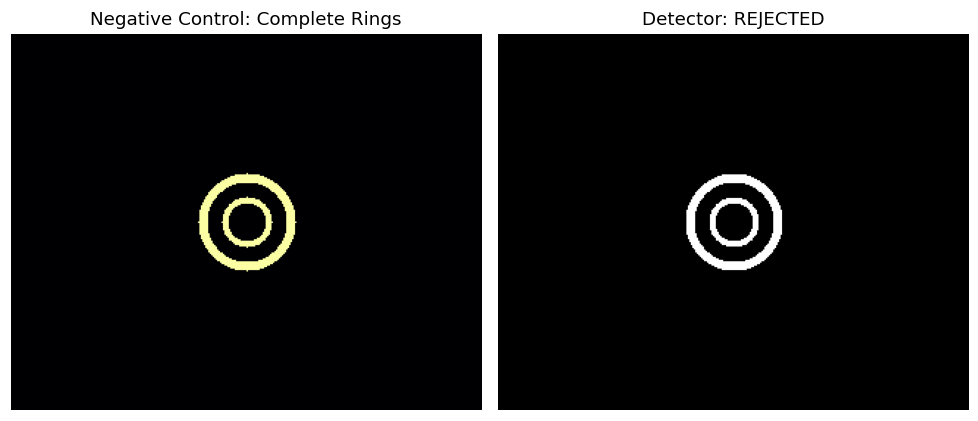

Detected as C: False


In [10]:
def create_two_complete_circles():
    temp = np.full(
        (HEIGHT, WIDTH),
        BACKGROUND_TEMP,
        dtype=np.float32
    )

    y, x = np.ogrid[:HEIGHT, :WIDTH]
    distance = np.sqrt(
        (x - CX) ** 2 + (y - CY) ** 2
    )

    outer = (
        (distance >= OUTER_RADIUS - OUTER_WIDTH / 2) &
        (distance <= OUTER_RADIUS + OUTER_WIDTH / 2)
    )

    inner = (
        (distance >= INNER_RADIUS - INNER_WIDTH / 2) &
        (distance <= INNER_RADIUS + INNER_WIDTH / 2)
    )

    temp[outer | inner] = TARGET_TEMP
    return temp


circle_temperature = create_two_complete_circles()
circle_result, circle_cleaned = run_detector(circle_temperature)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(
    circle_temperature,
    cmap="inferno",
    vmin=BACKGROUND_TEMP,
    vmax=TARGET_TEMP
)
axes[0].set_title("Negative Control: Complete Rings")
axes[0].axis("off")

axes[1].imshow(circle_cleaned, cmap="gray")
axes[1].set_title(
    "Detector: " +
    ("DETECTED" if circle_result else "REJECTED")
)
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Detected as C:", circle_result is not None)

---

# 12. Detection reliability

Each experimental condition is evaluated with **20 trials**.

\[
Detection\ Rate =
\frac{successful\ detections}{20}\times100
\]

The project uses **80%** as the predefined reliability criterion.

Examples:

- 20/20 = 100% → reliable
- 16/20 = 80% → reliable
- 15/20 = 75% → below the criterion
- 2/20 = 10% → poor

The 80% value is a project-level evaluation rule, not a universal thermal-imaging standard.

---

# 13. Experiment 1 — Distance

### Question
How does increasing target distance affect detection?

### Controlled condition

- 20 trials
- 15 °C contrast
- isolated distance test
- no simulated measurement noise
- no added blur

### Measured result

| Distance | Detection |
|---:|---:|
| 0.5 m | 20/20 = **100%** |
| 0.6 m | 20/20 = **100%** |
| 0.7 m | 20/20 = **100%** |
| 0.8 m | 0/20 = **0%** |
| 0.9 m and above | 0% in the tested range |

### Interpretation

The target remained reliably detectable through **0.7 m** in this synthetic setup and failed at 0.8 m.

This is a simulation result, not a measured real-camera working distance.

---

# 14. Experiment 2 — Blur

Distance was fixed at 0.5 m.

Gaussian blur kernels from:

`1×1, 3×3, 5×5, 7×7, 9×9, 11×11, 15×15, 21×21`

were tested.

### Result

**All tested blur levels were detected.**

### Interpretation

The current threshold + contour detector is tolerant to the tested blur.

This should **not** be interpreted as a real optical MTF result. Thresholding can turn a blurred edge into a usable binary contour again.

---

# 15. Experiment 3 — Thermal noise

Distance was fixed at 0.5 m. Each condition used 20 trials.

| Noise σ | Detection |
|---:|---:|
| 0.0 °C | 20/20 = **100%** |
| 0.5 °C | 20/20 = **100%** |
| 1.0 °C | 20/20 = **100%** |
| 1.5 °C | 20/20 = **100%** |
| 2.0 °C | 20/20 = **100%** |
| 3.0 °C | 20/20 = **100%** |
| 4.0 °C | 15/20 = **75%** |
| 5.0 °C | 2/20 = **10%** |
| 7.0 °C | 1/20 = **5%** |
| 10.0 °C | 0/20 = **0%** |

### Main finding

The detector maintained 100% detection through **σ = 3 °C**.

At 4 °C it dropped below the 80% criterion.

Therefore, the simulated 80% boundary lies **between 3 °C and 4 °C**.

### Limitation

This is not the measured NETD of a real camera. It is a simulated Gaussian-noise tolerance experiment.

---

# 16. Experiment 4 — Thermal contrast

The background was fixed at 25 °C.

Target temperatures were varied from 40 °C down to 26 °C, corresponding to:

`15, 13, 11, 9, 7, 5, 4, 3, 2, 1 °C`

### Result

All tested contrasts produced:

> **20/20 = 100% detection**

### Interpretation

In the idealized noiseless experiment, with the threshold adapted to the target/background pair, the minimum tested contrast of **1 °C** was still detected.

### Important limitation

This does **not** mean a real thermal camera can reliably resolve a 1 °C difference.

The test uses:

- synthetic data
- no measurement noise
- an adaptive threshold

Therefore it is an idealized contrast-recovery result.

---

# 17. Experiment 5 — Camera resolution

A fixed master target was generated at **640 × 512** and then downsampled.

This keeps the same target while changing the simulated sensor resolution.

| Resolution | Detection |
|---|---:|
| 640 × 512 | 20/20 = **100%** |
| 320 × 256 | 20/20 = **100%** |
| 160 × 128 | 20/20 = **100%** |
| 80 × 64 | 0/20 = **0%** |

### Main finding

> **160 × 128 was the lowest tested resolution achieving the predefined 80% reliability criterion.**

At 80 × 64 the detector failed in all 20 trials.

### Correct scientific wording

Say:

> “In our simulation, 160 × 128 was the lowest tested resolution achieving ≥80% detection reliability.”

Do not say:

> “A real thermal camera must have at least 160 × 128 resolution.”

In [11]:
MASTER_WIDTH, MASTER_HEIGHT = 640, 512

RESOLUTIONS = [
    (640, 512),
    (320, 256),
    (160, 128),
    (80, 64)
]


def create_master_target():
    temp = np.full(
        (MASTER_HEIGHT, MASTER_WIDTH),
        BACKGROUND_TEMP,
        dtype=np.float32
    )

    cx = MASTER_WIDTH // 2
    cy = MASTER_HEIGHT // 2

    outer = draw_c_mask(
        cx, cy, 100, 16,
        height=MASTER_HEIGHT,
        width_img=MASTER_WIDTH
    )

    inner = draw_c_mask(
        cx, cy, 50, 12,
        height=MASTER_HEIGHT,
        width_img=MASTER_WIDTH
    )

    temp[outer | inner] = TARGET_TEMP
    return temp


master_temperature = create_master_target()

resolution_results = []

for width, height in RESOLUTIONS:
    camera_temperature = cv2.resize(
        master_temperature,
        (width, height),
        interpolation=cv2.INTER_AREA
    )

    detected = 0

    for _ in range(20):
        result, _ = run_detector(camera_temperature)
        if result is not None:
            detected += 1

    rate = detected / 20 * 100

    resolution_results.append(
        (width, height, detected, rate)
    )

    print(
        f"{width} × {height} → "
        f"{detected}/20 ({rate:.1f}%)"
    )

640 × 512 → 0/20 (0.0%)
320 × 256 → 20/20 (100.0%)
160 × 128 → 20/20 (100.0%)
80 × 64 → 0/20 (0.0%)


---

# 18. Final results

| Experiment | Main variable | Main result |
|---|---|---|
| Distance | Range | Reliable through **0.7 m** in the isolated simulation |
| Blur | Gaussian blur | All tested levels detected |
| Noise | Gaussian noise | **100% through 3 °C**, 75% at 4 °C |
| Contrast | ΔT | 1 °C detected in the idealized noiseless test |
| Resolution | Sensor resolution | **160 × 128** lowest tested at ≥80% |

The central result is that a two-level concentric-C thermal target can be recognized using **classical contour-based computer vision** without machine learning, under the simulated conditions.

---

# 19. What the experiments tell us

### Distance
The target becomes smaller in the image as distance increases. Eventually its geometric structure is no longer preserved well enough for reliable detection.

### Blur
The current detector is tolerant to the tested blur levels. This is mainly a property of the processing pipeline, not proof of real optical performance.

### Noise
Noise eventually damages the target geometry and introduces incorrect pixels.

### Contrast
The idealized contrast test shows that the algorithm can recover very small temperature differences when noise is removed and the threshold is adapted.

### Resolution
A clear simulated resolution boundary was observed between 160 × 128 and 80 × 64.

Together, these experiments connect **thermal signal, spatial sampling, image degradation, and geometric detection**.

---

# 20. Why the combined-condition experiment is not used as a final physical threshold

A combined experiment was also explored using distance, noise, and contrast together.

Some results were non-monotonic. For example, at 0.7 m and 15 °C contrast, adding simulated noise changed the detector result from 0% to 65%.

This does not mean that noise physically improves visibility.

It indicates an interaction between:

- random pixels
- thresholding
- morphology
- contour geometry

Therefore, the combined-condition experiment is treated as a **detector-behaviour diagnostic**, not a physical performance threshold.

---

# 21. Limitations

This study is a **controlled simulation**, not a complete characterization of a real thermal camera.

### Synthetic data
Real thermal cameras have effects such as sensor non-uniformity, calibration error, lens behaviour, atmospheric effects, emissivity, and real spatial response. These are not fully represented.

### Blur
The blur experiment does not measure real optical MTF.

### Contrast
The 1 °C result is idealized because noise is disabled and the threshold is adapted.

### Noise
The Gaussian noise model is a simplified NETD-style abstraction, not a laboratory NETD measurement.

### Resolution
The 160 × 128 result is specific to this target, simulation, and detector. It is not a universal minimum resolution.

### Detector dependence
The measured “acuity” is partly a property of the complete **simulation + preprocessing + contour detector** system.

---

# 22. Reproducibility

The notebook uses a fixed seed where random behaviour is required:

```python
RNG_SEED = 42
```

Repeated experiments use **20 trials per condition**.

The main parameters are defined near the beginning of the notebook.

For a future real-camera study, the synthetic temperature maps can be replaced with measured thermal images while keeping the same evaluation logic.

This makes the notebook a bridge between:

```text
simulation
   ↓
controlled experiment
   ↓
real thermal-camera validation
```

---

# 23. Final conclusion

This study developed a simple physics-based thermal imaging simulation and a classical computer vision detector for a **two-level concentric-C target**.

The target contains two concentric C-shaped rings with a common center and common opening direction.

The study found:

- reliable detection through **0.7 m** in the isolated distance simulation
- tolerance to the tested blur levels
- **100% detection through 3 °C simulated noise**
- detection down to **1 °C contrast under an idealized noiseless condition**
- **160 × 128** as the lowest tested resolution achieving ≥80% detection reliability

These are **simulation-based results**. They should not be presented as direct measurements of a real thermal camera.

The main contribution of this study is the reproducible connection between:

```text
Target geometry
      ↓
Thermal signal
      ↓
Image formation
      ↓
Image degradation
      ↓
Classical computer vision
      ↓
Detection reliability
```

The next scientific step is validation with **real thermal-camera images** of the physical concentric-C target.

---

# Appendix — Key terms

| Term | Simple meaning |
|---|---|
| Thermal contrast (ΔT) | Temperature difference between target and background |
| Thermal noise | Random temperature measurement variation |
| NETD | Noise Equivalent Temperature Difference |
| Blur | Spreading of image detail |
| Spatial resolution | Ability to preserve small spatial features |
| IFOV | Angular area represented by one detector pixel |
| Contour | Boundary extracted from a binary image |
| Classical CV | Rule-based computer vision using geometry, thresholding, contours, etc. |
| Detection rate | Percentage of repeated trials that detect the target |
| Concentric | Sharing the same center |
| Two-level C | Outer C + inner C |
| 80% reliability | Predefined reliability criterion used in this study |